# Factor risk model diagnostics

Regression uses X_(t-1) for r_t; covariance uses trailing factor returns through t. Repair and conditioning are auditable.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display
from risk_aware_portfolio.utils.config import load_config
from risk_aware_portfolio.utils.paths import resolve_path
config = load_config()
display(pd.read_csv(resolve_path("outputs/tables/risk_summary.csv")))
display(pd.read_csv(resolve_path("outputs/tables/factor_return_recovery.csv")))
display(pd.read_parquet(resolve_path("data/interim/regression_diagnostics.parquet")).describe())


,portfolio,average_predicted_volatility,realized_gross_volatility,mean_squared_return_to_variance,qlike,average_factor_risk_fraction,average_specific_risk_fraction,maximum_repair_variance_adjustment
0,Baseline,0.109389,0.104859,0.976609,-8.992200,0.768410,0.231590,3.049319e-20
1,Risk-Aware Portfolio,0.082095,0.079722,0.995792,-9.539414,0.859294,0.140706,2.414044e-20
2,Risk-Aware + TC,0.081475,0.079444,1.004612,-9.546221,0.867839,0.132161,2.117582e-20
3,Neutralized Alpha Portfolio,0.078671,0.077174,1.007341,-9.613109,0.860473,0.139527,1.990527e-20


,factor,correlation,rmse,mean_error
0,market,0.798858,0.003134,-0.000006
1,industry:industry_1,0.612868,0.004911,0.000019
2,industry:industry_2,0.651940,0.004723,-0.000155
3,industry:industry_3,0.659814,0.004610,0.000324
4,size,0.886979,0.002080,-0.000159
5,value,0.913931,0.001741,0.000200
6,momentum,0.894836,0.001919,-0.000026
7,volatility,0.893079,0.002014,-0.000031
8,liquidity,0.925851,0.001628,0.000106


,rank,n_assets,condition_number,weighted_r_squared,residual_std
count,314.0,314.0,314.000000,314.000000,314.000000
mean,9.0,60.0,6.469112,0.451463,0.011810
std,0.0,0.0,0.499188,0.153536,0.001404
min,9.0,60.0,5.534641,0.048061,0.008143
25%,9.0,60.0,6.133595,0.345425,0.010959
50%,9.0,60.0,6.383909,0.458191,0.011790
75%,9.0,60.0,6.738008,0.564784,0.012631
max,9.0,60.0,8.011928,0.808966,0.017184


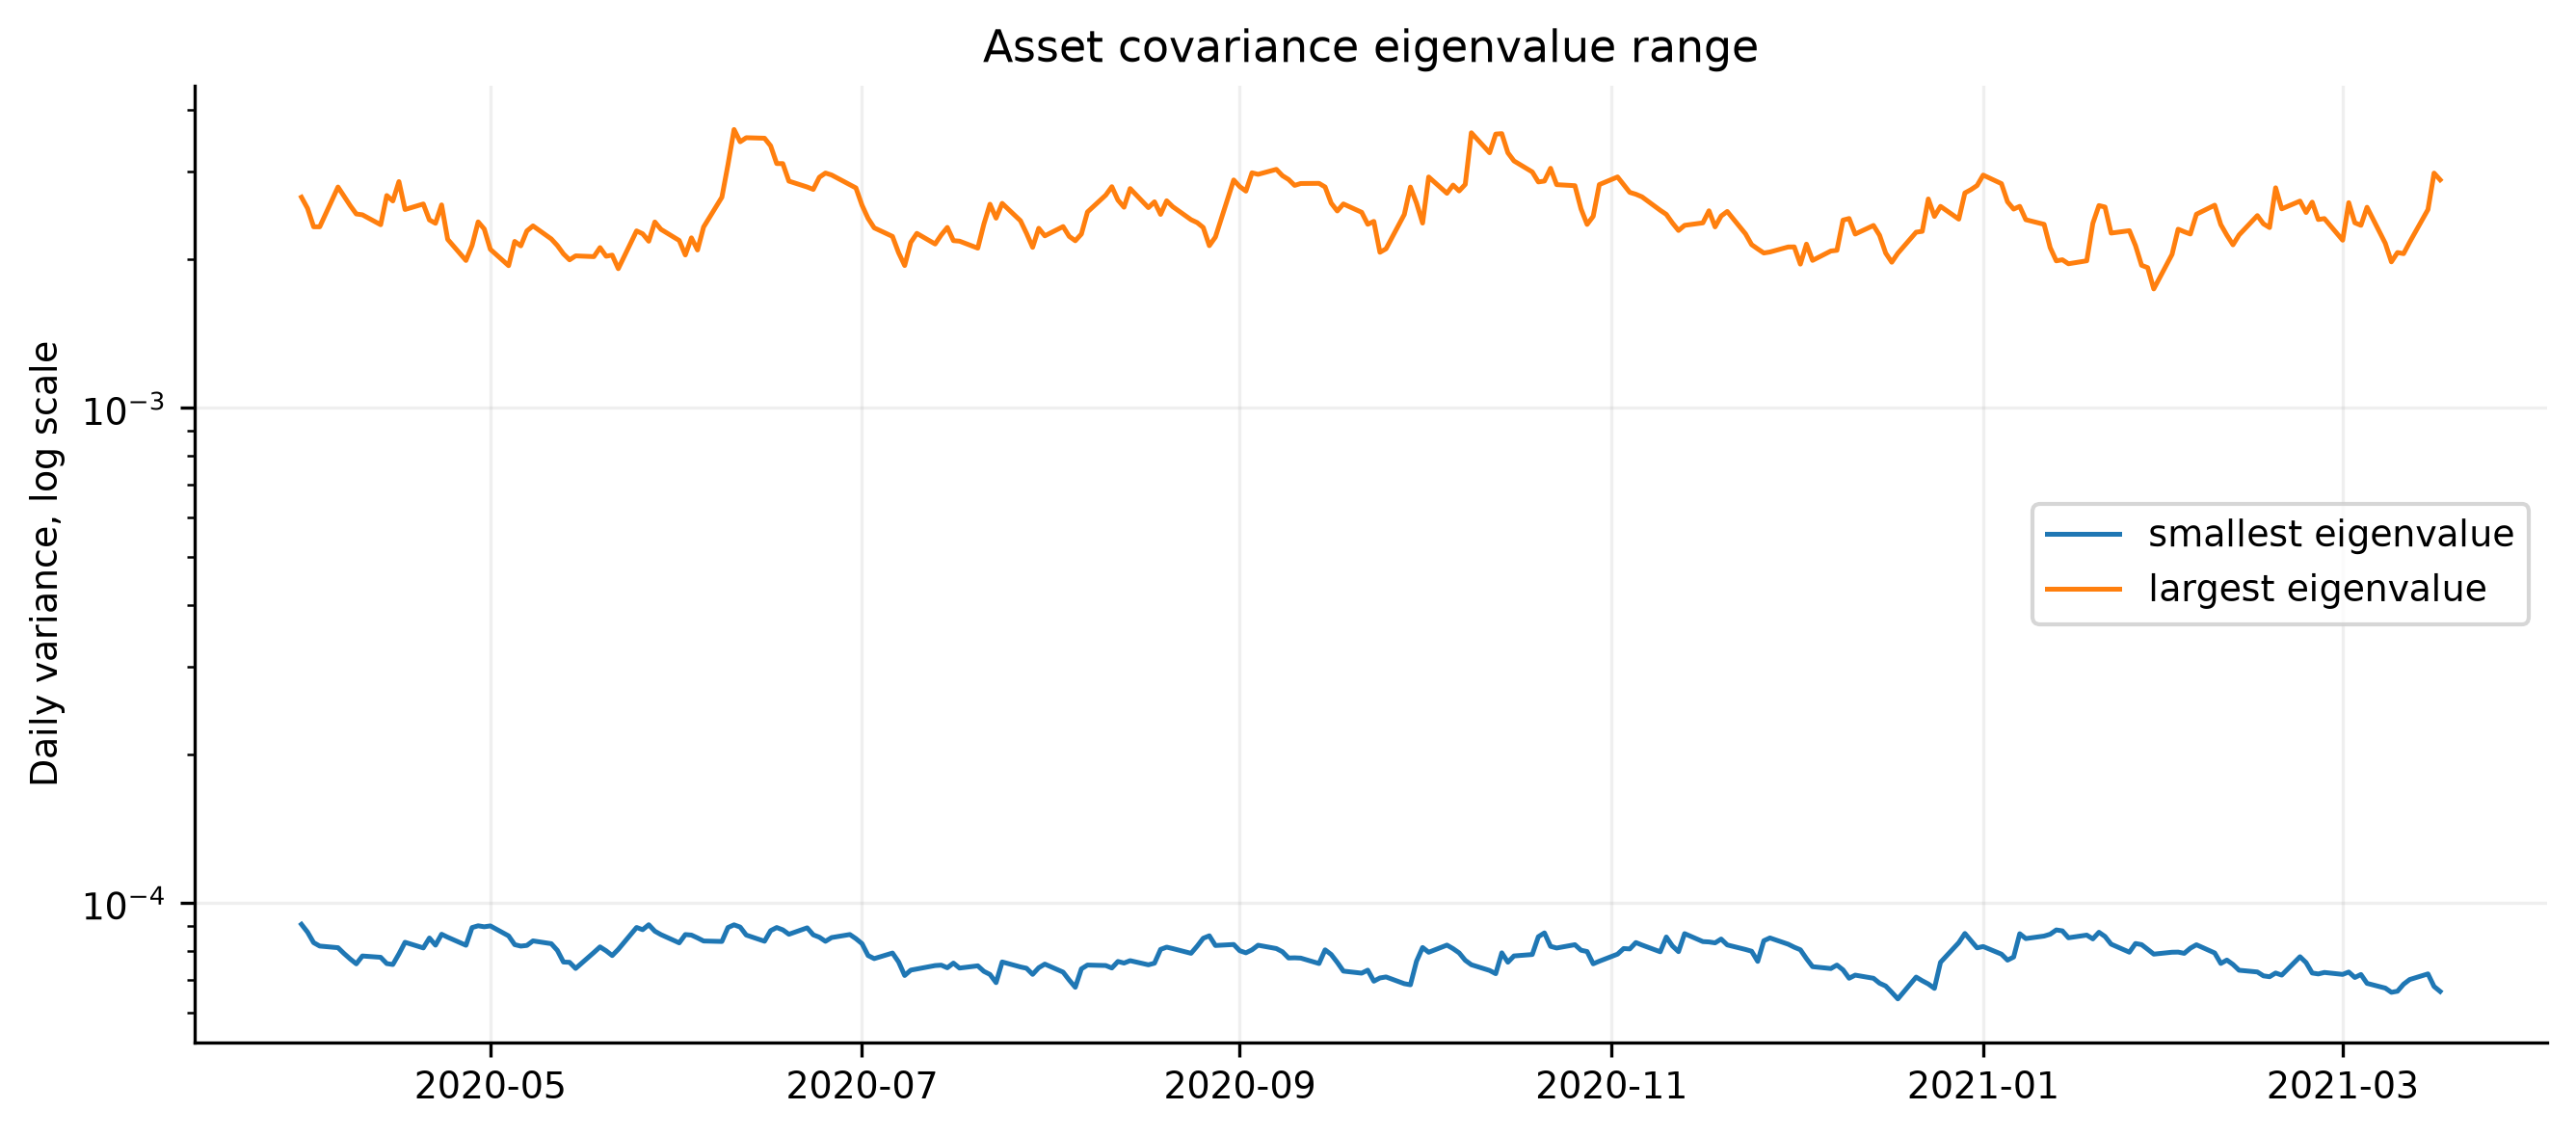

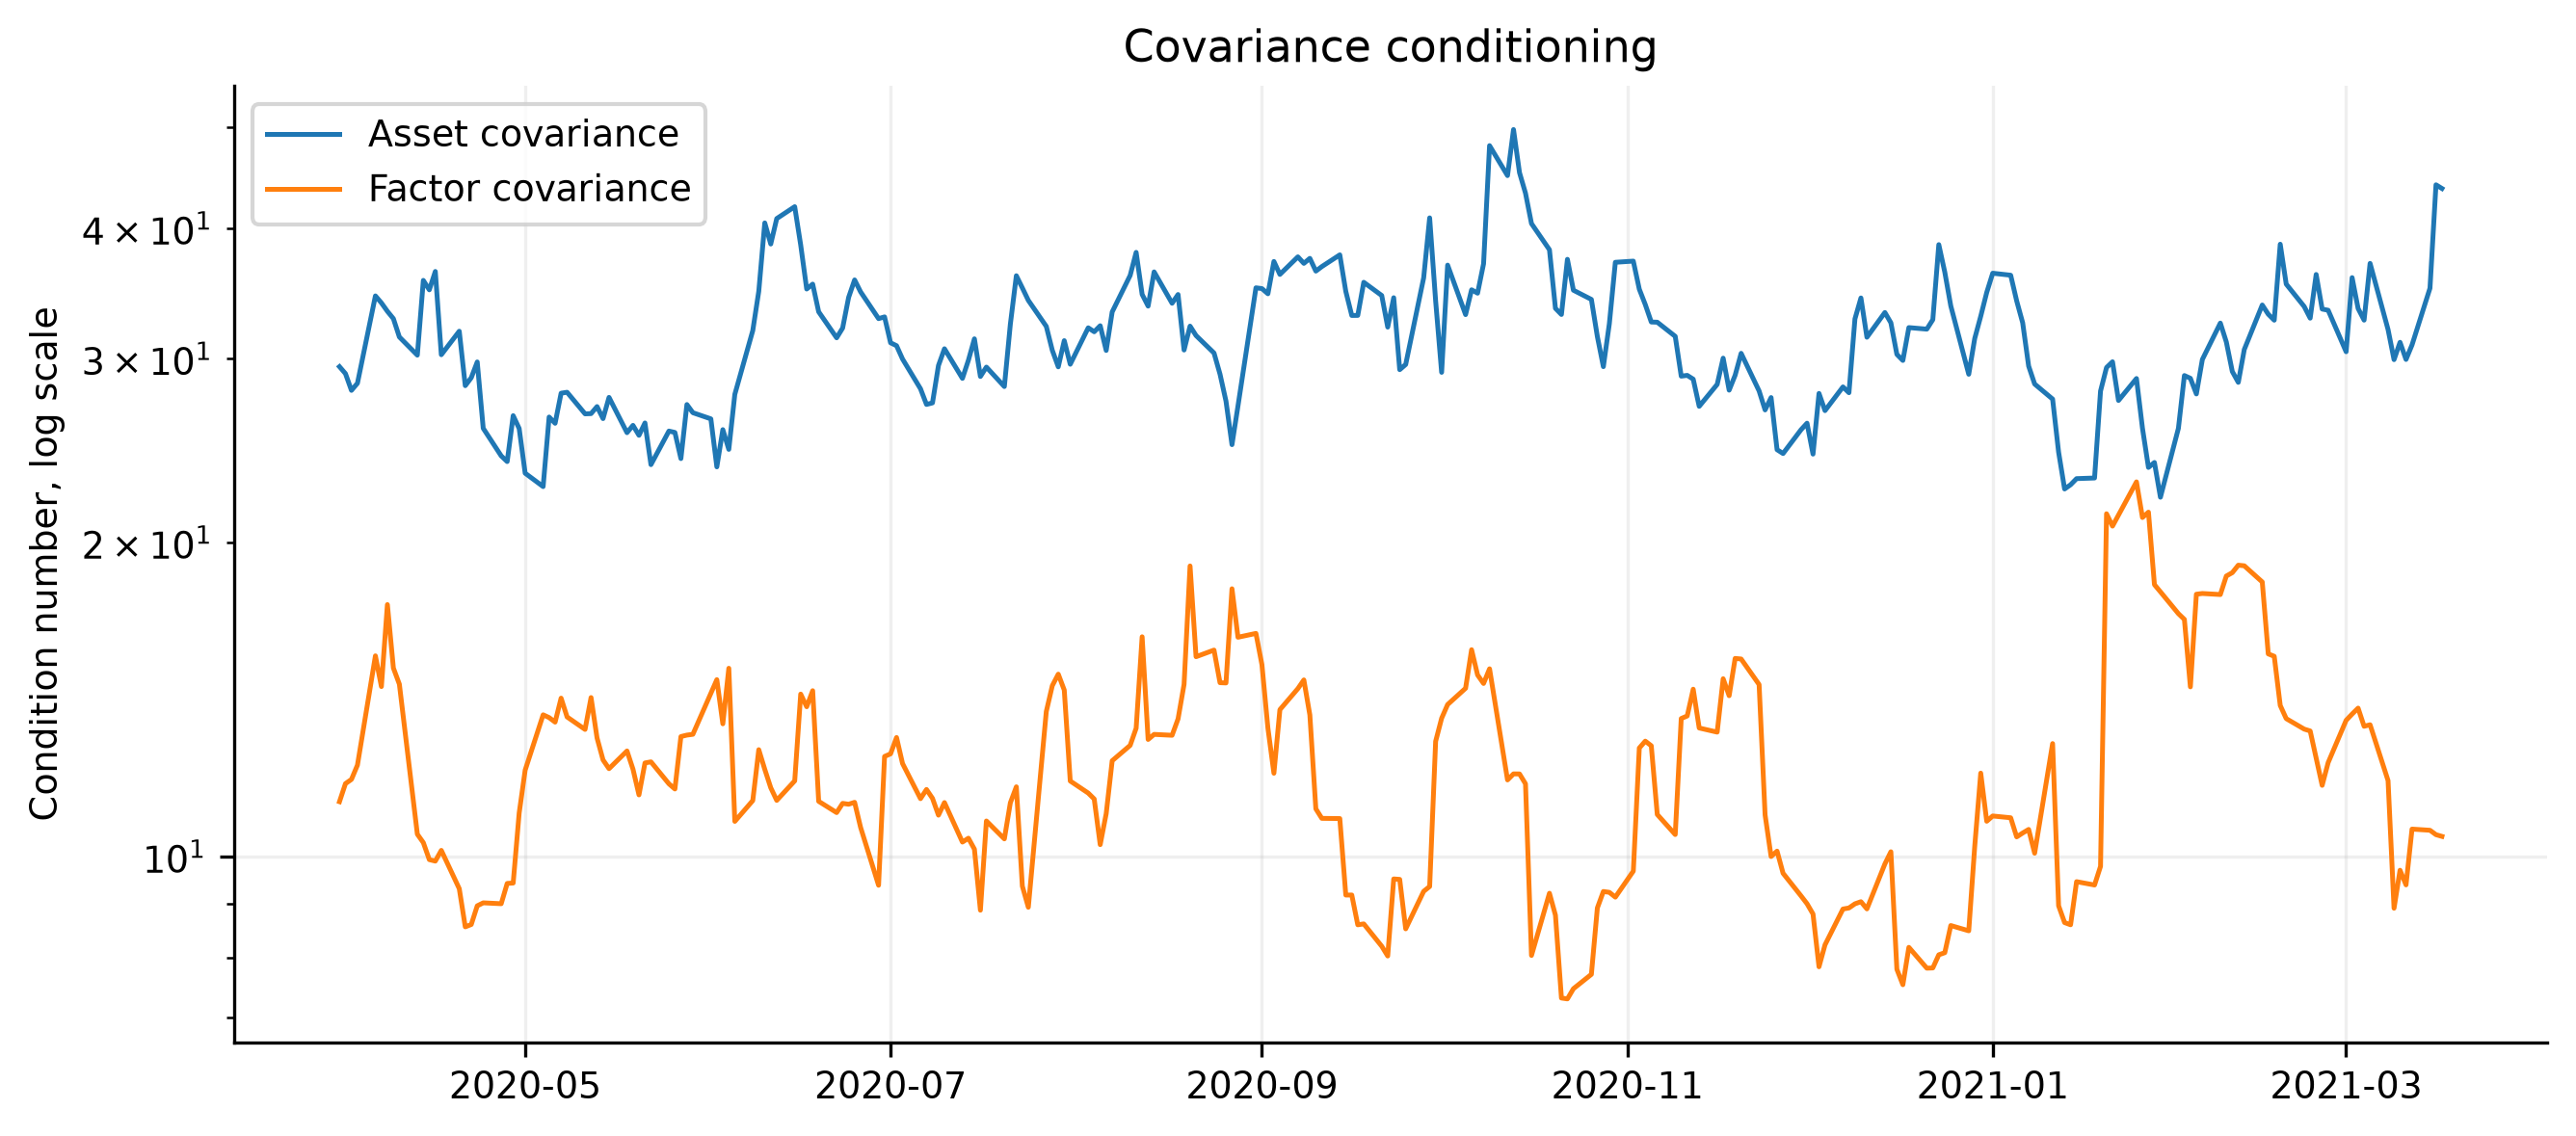

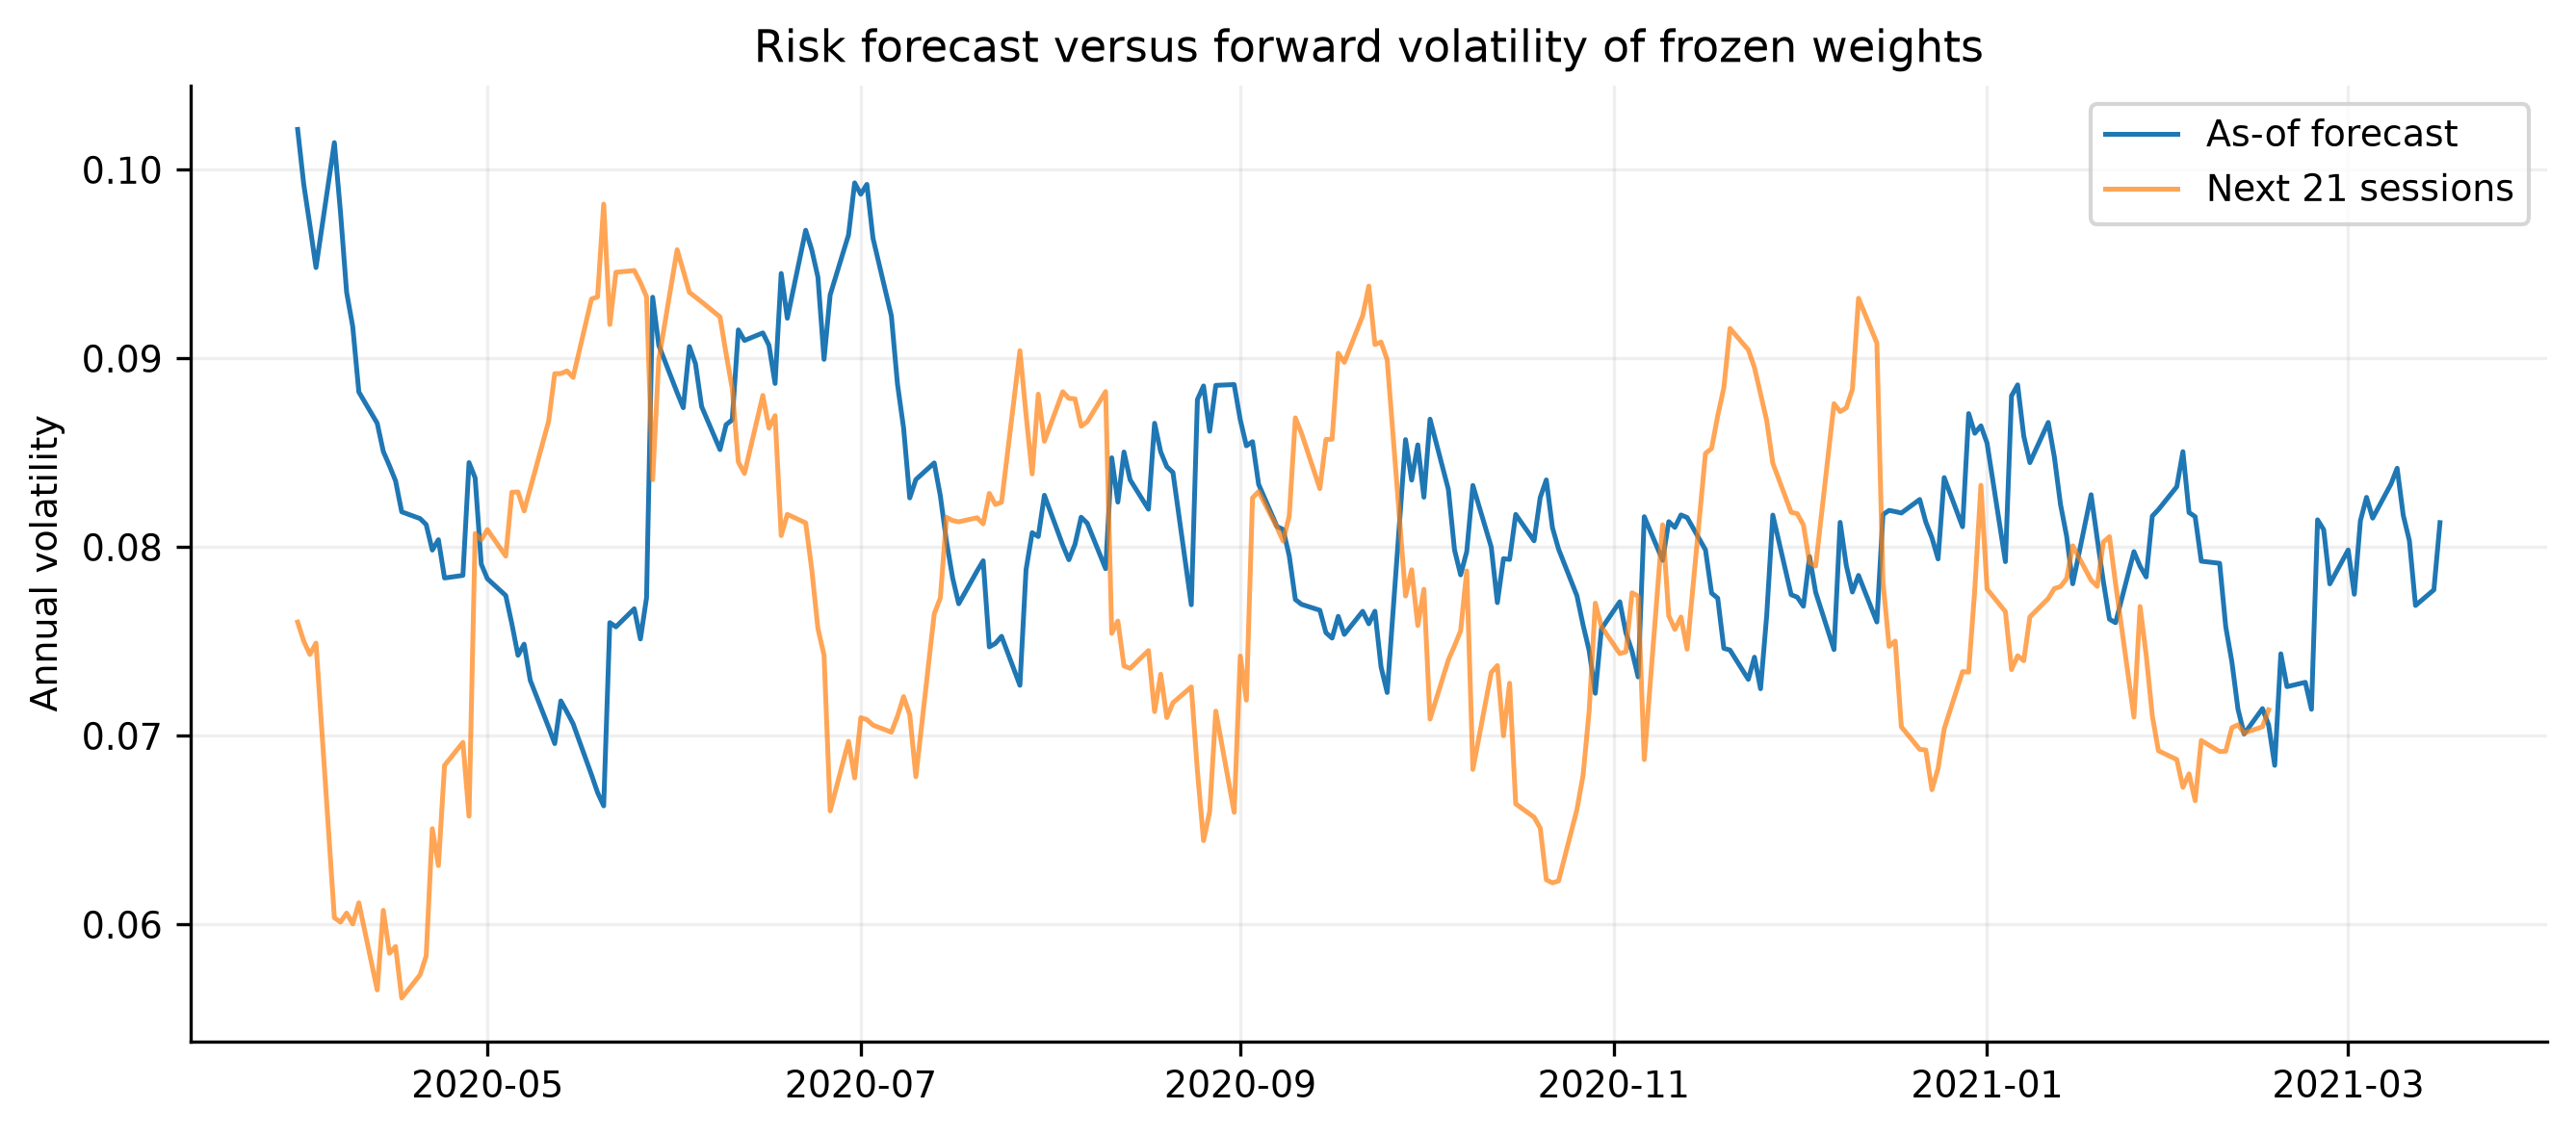

In [2]:
for name in ["covariance_eigenvalues", "covariance_condition_number", "predicted_vs_realized_risk"]:
    display(Image(filename=str(resolve_path(f"outputs/figures/{name}.png")), width=850))


Forward realized volatility freezes today's weights for the next 21 sessions. Overlapping windows and ex-post bins are diagnostic only. Regression factors can absorb the part of true synthetic alpha aligned with risk exposures.

In [3]:
display(pd.read_csv(resolve_path("outputs/tables/risk_calibration_buckets.csv")))


,bucket,predicted_volatility,realized_volatility,n_observations,realized_to_predicted
0,0,0.073440,0.083870,47,1.142021
1,1,0.078000,0.080826,46,1.036228
2,2,0.080948,0.074378,46,0.918839
3,3,0.084352,0.073516,46,0.871546
4,4,0.092138,0.076244,46,0.827503
